# How often does it pay to go for it on 4th down?
**Project 1 – Applied Probability.** Which rule for when to go for it on 4th down wins the most games?
We estimate probabilities from NFL play-by-play data (2018–2025), simulate whole games as a Markov chain, and compare
strategies with Monte Carlo.

This notebook only **shows** the results. The simulations are run in `compute.ipynb`, which saves `results.json`.

In [1]:
import pandas as pd
import model as M
import plots as P

m = M.estimate(M.load_data())          # probabilities from the data (a few seconds)
res = M.load_results("results.json")   # simulation results from compute.ipynb
best = M.build(res["best"], res["fg_range"])
print(f"Best strategy: {res['best_name']}  (field goals up to {res['best_k']} yards)")
res["final"].loc[[res["best_name"]], ["p̂", "diff (pp)", "diff lower", "diff upper"]].round(3)

Best strategy: ≤4 yd + no man's land 40–45 + goal line + trailing (≤2 drives) | else kick  (field goals up to 61 yards)


,p̂,diff (pp),diff lower,diff upper
≤4 yd + no man's land 40–45 + goal line + trailing (≤2 drives) | else kick,0.545,4.481,4.07,4.892


## 1. Probabilities from the data
**Yards per play.** Yards gained $Y$ is skewed: a point mass at 0 (mostly incomplete passes) and a long right tail.
The simulator stores every real play per (down, yards to go) and **samples** from it; 3rd and 4th down are pooled.

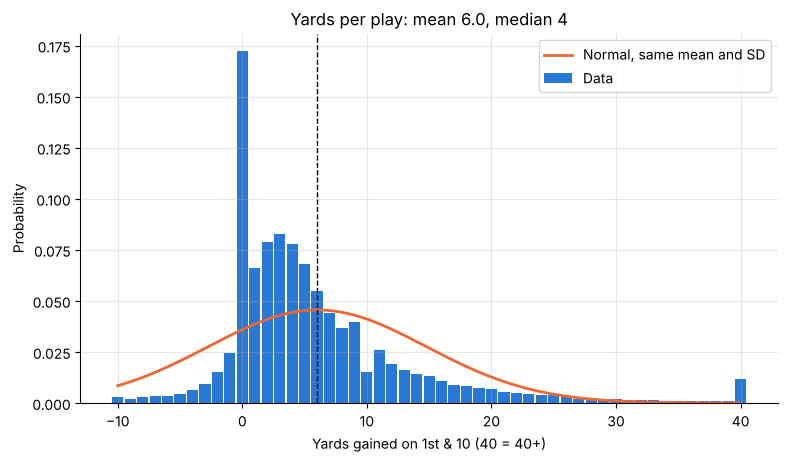

In [2]:
P.yards_per_play(m)

**Probability of a 1st down**, $p(d) = P(\text{1st down} \mid d)$: a proportion per $d$, standard error $\sqrt{\hat p(1-\hat p)/n} < 0.01$.

In [3]:
m["p_d"].loc[1:10].T.round(3)

ydstogo,1,2,3,4,5,6,7,8,9,10
mean,0.7,0.576,0.529,0.488,0.434,0.429,0.384,0.355,0.305,0.294
count,5641.0,3456.000,3178.000,3034.000,3092.000,2891.000,2731.000,2459.000,2079.000,2588.000


**Field goals.** $p_{FG}(x)$ comes from a **logistic regression** $p(x) = 1/(1+e^{-(\beta_0+\beta_1 x)})$,
fitted by maximum likelihood to every kick ($x \approx pos + 18$). The dots show the raw make rate per distance.

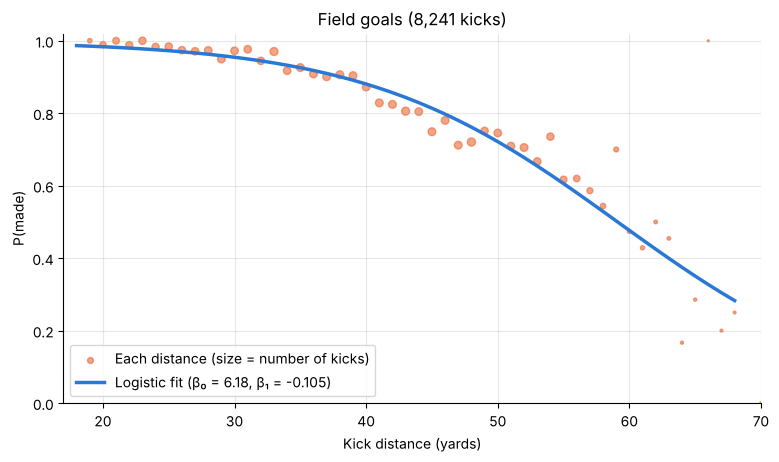

In [4]:
P.field_goals(m)

**Real coaches** (strategy 1, and always the opponent): $P(\text{go} \mid \text{yards to go, pos})$ per cell.
Coaches almost always go on 4th & 1 around midfield, but rarely on their own half.

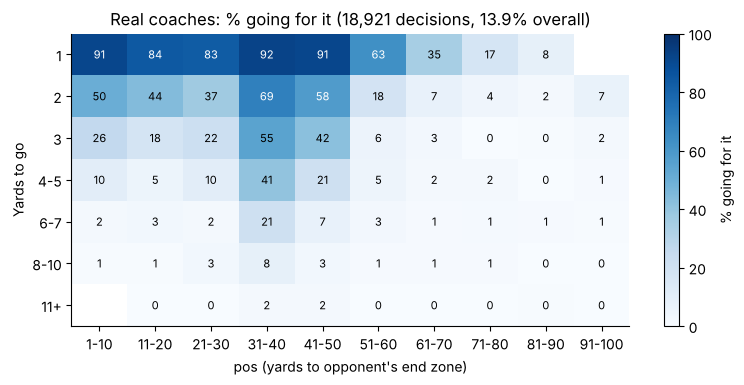

In [5]:
P.coach_go_rates(m)

## 2. Does the simulator work?
A drive is a Markov chain on (down, yards to go, pos). A game is 11 drives per team, no clock.
**Coach vs coach** should give 50% (test of $H_0: p = 0.5$), and simulated $p(d)$ and drive outcomes should match the data.

Coach vs coach: p̂ = 0.5021 [0.4978, 0.5064], p-value = 0.34


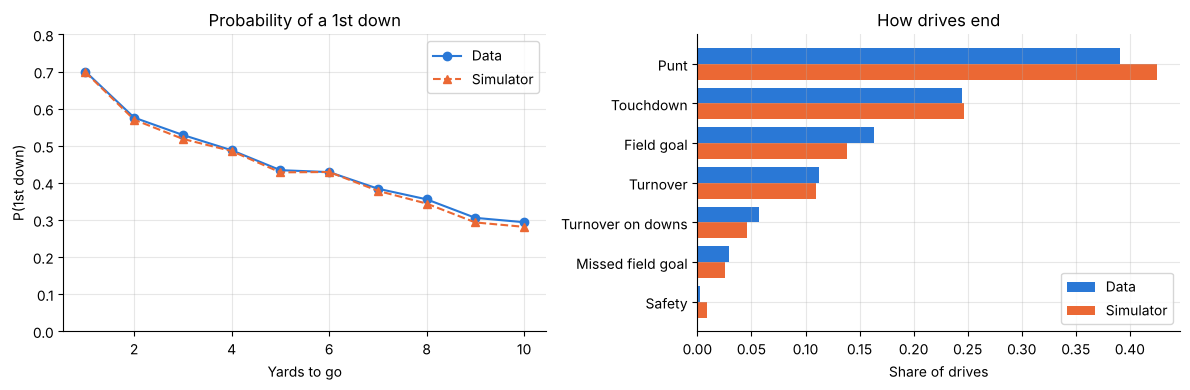

In [6]:
p, lo, hi, pval = res["coach_vs_coach"]
print(f"Coach vs coach: p̂ = {p:.4f} [{lo:.4f}, {hi:.4f}], p-value = {pval:.2f}")
P.validation(res)

The p-value is far from significant, so the simulator has no built-in bias. A few more punts in the simulator,
because real drives also end at halftime, which we don't model.

## 3. Step 1: each strategy on its own
Each game is a Bernoulli trial (win 1, tie ½, loss 0). Game $i$ uses the same random numbers for every strategy,
so differences are **paired**: $D_i = X_i^A - X_i^B$, 95% CI by the CLT.

**How far should we try field goals?**

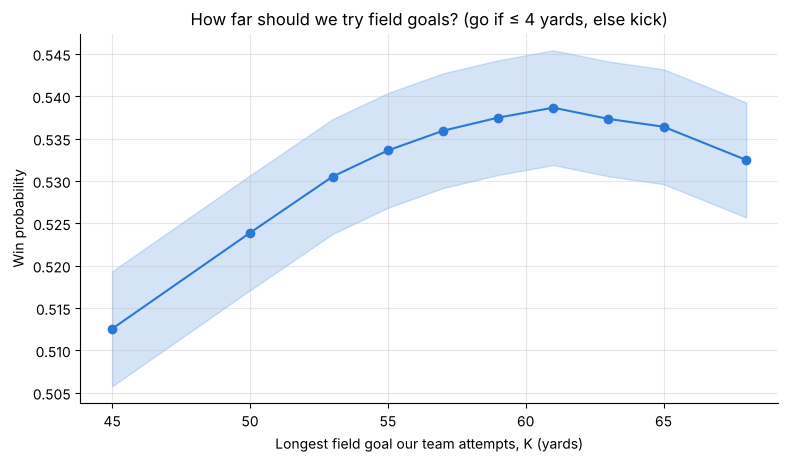

Best K = 61 yards, P(made) there = 45%


In [7]:
P.fg_sweep(res)
print(f"Best K = {res['best_k']} yards, P(made) there = {m['p_fg'][res['fg_range']]:.0%}")

Trying longer field goals helps up to about 61 yards. Beyond that, the misses cost more than the points gained.

**Aggressiveness:** going for it at random (orange) never beats the coaches. Going for it on short yardage (blue) does:
**where** you go for it matters, not how often.

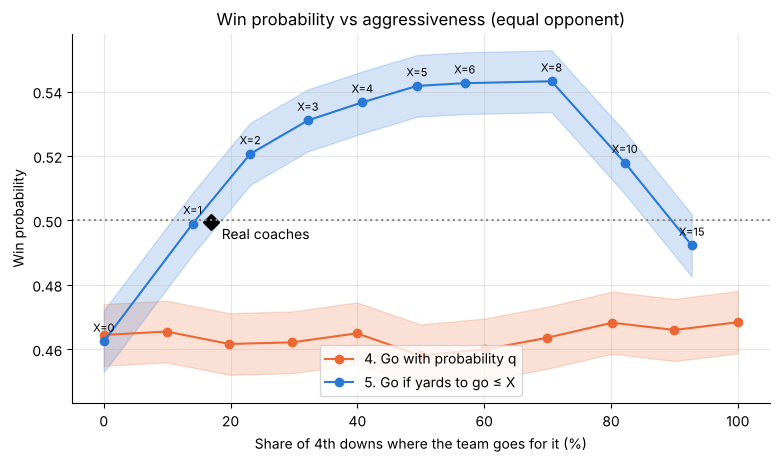

In [8]:
P.aggressiveness(res)

**Short and close** (yards to go ≤ X and pos ≤ Y): restricting attempts to near the goal hurts; the best cells form a broad plateau.

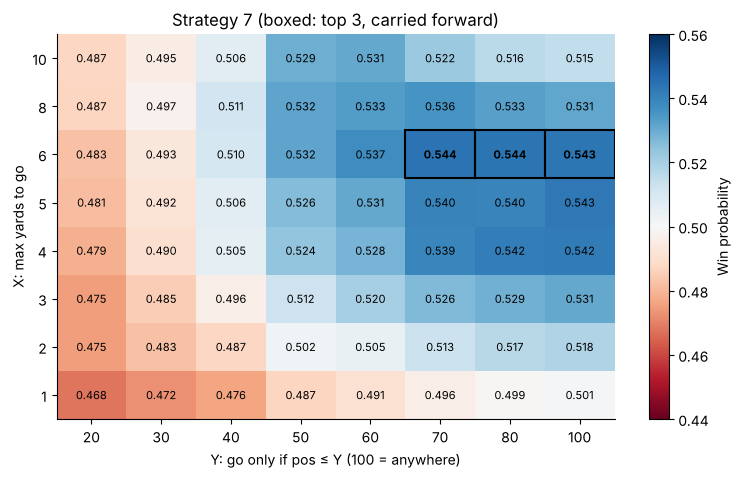

In [9]:
P.short_and_close(res)

**No man's land:** with field goals up to 61 yards it almost disappears. Adding it on top of short yardage gains little (about 0.3 pp).

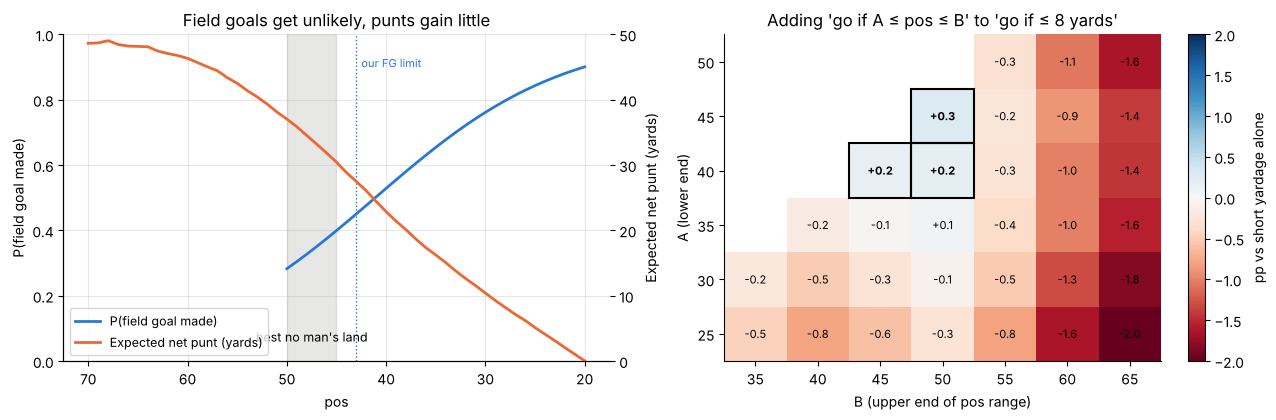

In [10]:
P.no_mans_land(m, res)

**Trailing late** (go when behind with ≤ N drives left), win probability:

In [11]:
res["sweep_n"].T.round(3)

,1,2,3,4,6,8,12
p̂,0.482,0.488,0.494,0.496,0.496,0.497,0.501


**All single strategies** (30,000 paired games). Only the yards-to-go rules beat the coaches by more than about 1 pp on their own.

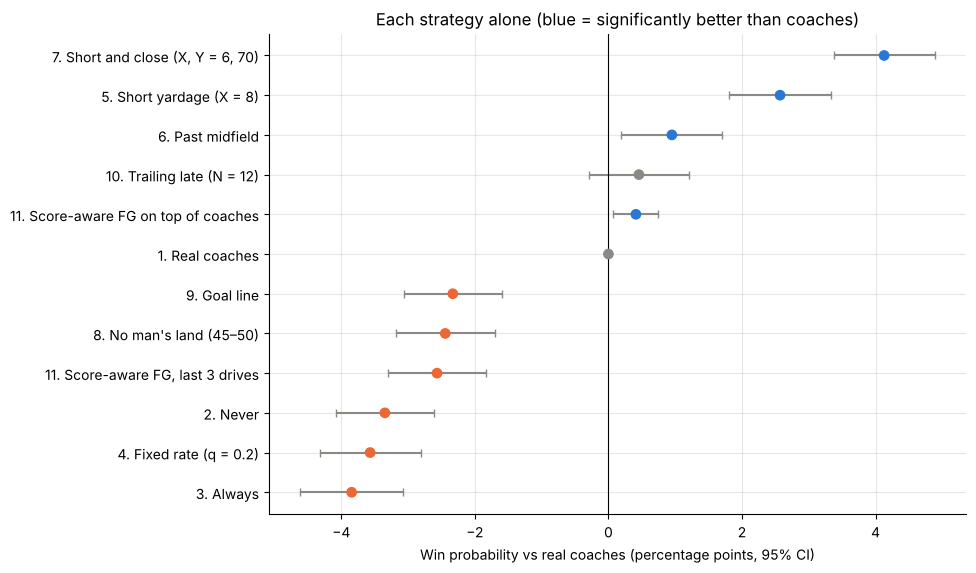

,p̂,diff (pp),diff lower,diff upper,go %
1. Real coaches,0.500,0.000,0.000,0.000,16.807
2. Never,0.467,-3.347,-4.081,-2.612,0.000
3. Always,0.462,-3.845,-4.611,-3.079,100.000
4. Fixed rate (q = 0.2),0.464,-3.568,-4.325,-2.811,19.944
5. Short yardage (X = 8),0.526,2.570,1.811,3.329,70.318
6. Past midfield,0.510,0.950,0.195,1.705,47.320
"7. Short and close (X, Y = 6, 70)",0.541,4.128,3.373,4.883,50.005
8. No man's land (45–50),0.476,-2.443,-3.182,-1.704,7.921
9. Goal line,0.477,-2.330,-3.065,-1.595,2.961
10. Trailing late (N = 12),0.505,0.457,-0.289,1.203,50.270


In [12]:
P.diffs(res["singles"], "Each strategy alone (blue = significantly better than coaches)")
res["singles"].round(3)

## 4. Step 2: the best combination
**Successive halving:** play all candidates on a few games, keep the best quarter, play the survivors on 4× more games, repeat.

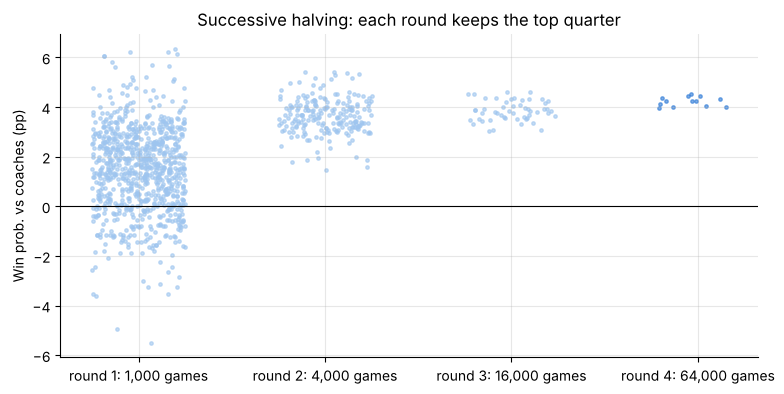

In [13]:
P.halving(res)

**Which rules matter?** Regression of each candidate's gain on 0/1 indicators of its rules:
$\beta_r$ = average change in win probability from adding rule $r$.

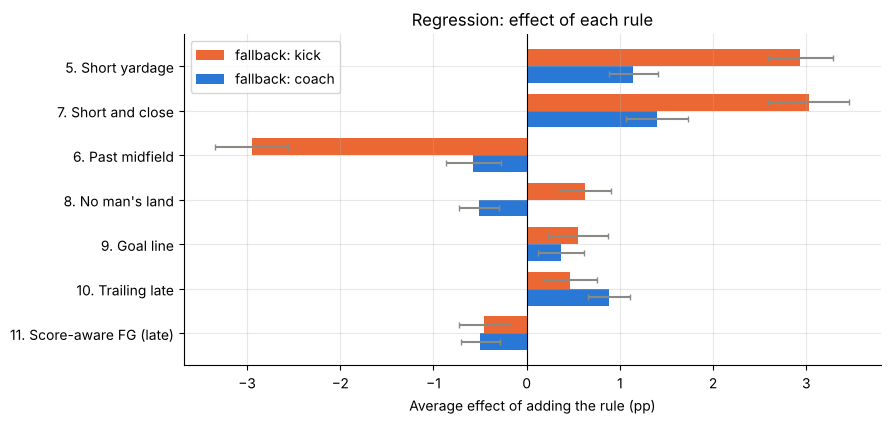

In [14]:
P.effects(res)

**Final check** (100,000 paired games, fresh random numbers):

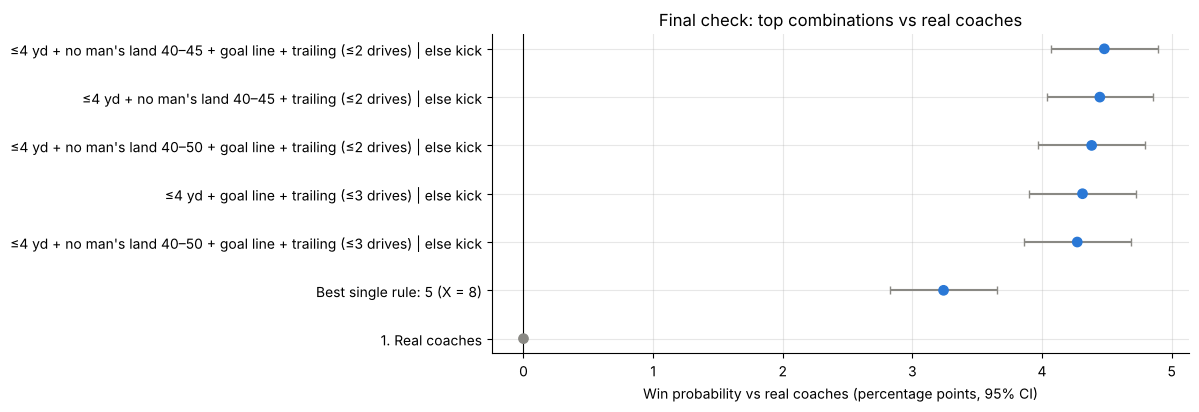

Best combination − best single rule = 1.24 pp [0.89, 1.59]


In [15]:
P.diffs(res["final"], "Final check: top combinations vs real coaches")
print("Best combination − best single rule = {:.2f} pp [{:.2f}, {:.2f}]".format(*res["best_vs_single"]))

## 5. Step 3: opponent strength
Strong / weak opponent = plays only from the top / bottom third of teams by EPA per play.
The stronger the opponent, the more aggression pays.

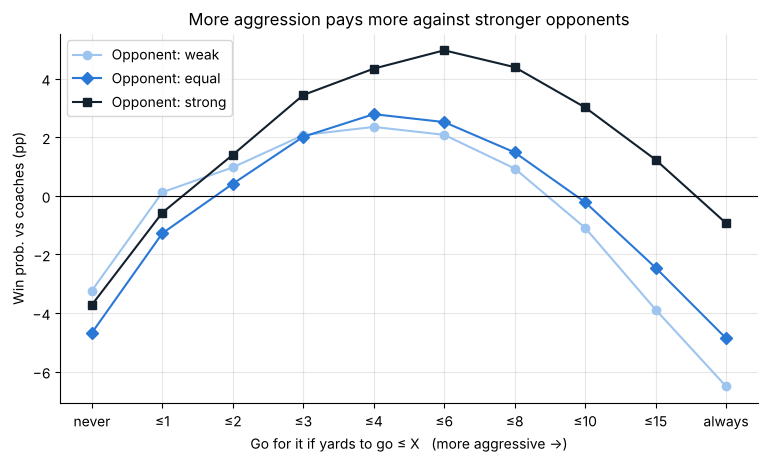

,weak,equal,strong
best single (≤8 yd),1.4,3.0,4.5
best combination,3.1,4.5,5.2


In [16]:
P.opponents(res)
res["opp_res"].round(1)

## 6. The handbook
What the best strategy does on every 4th down in a normal situation (tied game, not late), next to what coaches usually do.

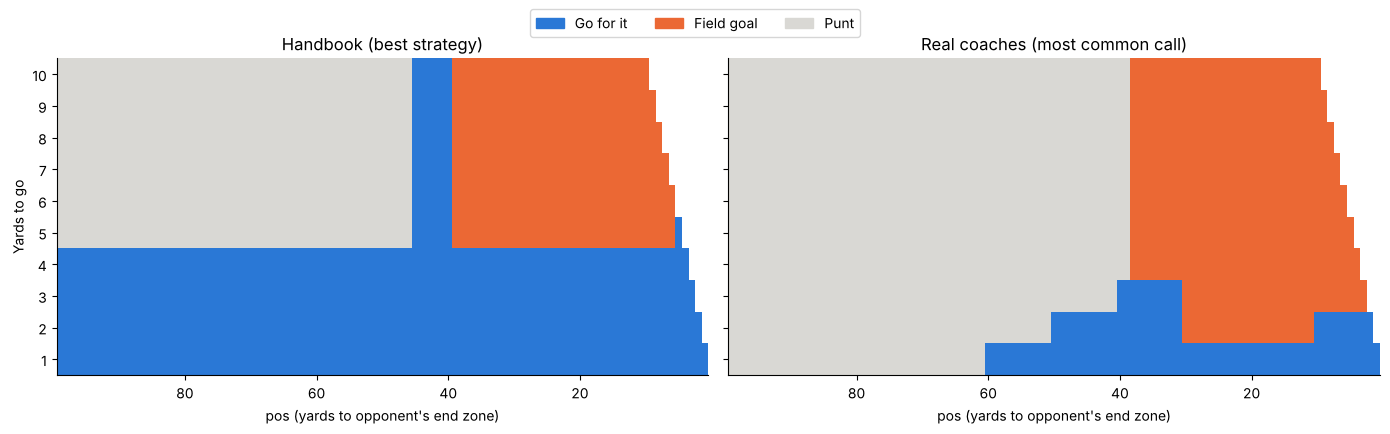

In [17]:
hb = M.handbook(m, best)
P.handbook_map(hb)

**The handbook in one table:** in each zone, go for it with this many yards to go or fewer.

In [18]:
M.go_thresholds(hb)

,go if yards to go ≤,otherwise
pos (yards to end zone),,
1-10,5,fg
11-20,4,fg
21-30,4,fg
31-40,15,fg
41-50,15,punt
51-60,4,punt
61-70,4,punt
71-80,4,punt
81-90,4,punt


**Look up any situation** (change the numbers):

In [19]:
hb.query("togo == 4 and pos == 55").round(2)

,togo,pos,call,P(1st down),FG distance,P(FG good),coaches go %,coaches usually
345,4,55,go,0.49,73,0.0,5.04,punt


## 7. Conclusions
1. Both extremes lose, and so does random aggressiveness: **where** you go for it matters, not how often.
2. Short yardage is the main driver: "go if ≤ 6 yards to go and pos ≤ 70" alone gives about +4 pp.
3. Kick longer field goals: trying up to ~61 yards beats stopping at 55.
4. Combining helps a little: the best combination (≤ 4 yards, plus no man's land 40–45, goal line and trailing late)
   gives about +4.5 pp, only slightly more than the best single rule.
5. The stronger the opponent, the more aggression pays.

**Caveats:** no clock or penalties; the opponent does not adapt; 4th downs modelled with 3rd-down plays; opponent
strength only affects its offense. Results compare strategies; they are not exact win probabilities.